# ### # ETAPA 1. Carga de datos

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv(
    "Ejercicio ABCXYZ Blank.csv",
    sep=";",
    encoding="utf-8-sig"   # elimina el BOM (\ufeff) del inicio
)

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 776 entries, 0 to 775
Data columns (total 59 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Código           775 non-null    object 
 1   Descripción      775 non-null    object 
 2   Familia          775 non-null    object 
 3   Grupo            775 non-null    object 
 4   Línea            775 non-null    object 
 5   Costo Ordenar    775 non-null    float64
 6   Costo Almacenar  775 non-null    object 
 7   sep-18           775 non-null    float64
 8   oct-18           775 non-null    float64
 9   nov-18           775 non-null    float64
 10  dic-18           775 non-null    float64
 11  ene-19           775 non-null    float64
 12  feb-19           775 non-null    float64
 13  mar-19           775 non-null    float64
 14  abr-19           775 non-null    float64
 15  may-19           775 non-null    float64
 16  jun-19           775 non-null    float64
 17  jul-19          

,Código,Descripción,Familia,Grupo,Línea,Costo Ordenar,Costo Almacenar,sep-18,oct-18,nov-18,...,mar-19.1,abr-19.1,may-19.1,jun-19.1,jul-19.1,ago-19.1,Vr Unit,Inventario,Pedidos,WIP Planta
0,446189,REFERENCIA 184,FAMILIA 35,GRUPO 1,LINEA 1,784000.0,"0,20",19339492.0,6608834.0,35221608.0,...,541.0,10750.0,517.0,256.0,190.0,252.0,28572.0,2112.0,48.0,0.0
1,393292,REFERENCIA 70,FAMILIA 39,GRUPO 2,LINEA 2,1092000.0,"0,20",32724864.0,37537344.0,29516544.0,...,1344.0,1344.0,2028.0,1344.0,2280.0,3036.0,13368.0,4190.0,12.0,0.0
2,419053,REFERENCIA 108,FAMILIA 2,GRUPO 3,LINEA 3,252000.0,"0,20",24021363.0,22107737.0,20479371.0,...,2011.0,2379.0,2391.0,2288.0,2558.0,1580.0,10524.0,5524.0,3.0,0.0
3,465937,REFERENCIA 283,FAMILIA 2,GRUPO 3,LINEA 3,252000.0,"0,20",20277516.0,18114264.0,19695102.0,...,1715.0,2268.0,2289.0,2660.0,2359.0,1405.0,10524.0,6058.0,6.0,0.0
4,407593,REFERENCIA 82,FAMILIA 6,GRUPO 3,LINEA 3,252000.0,"0,20",20326200.0,30410799.0,28537329.0,...,1032.0,1024.0,1136.0,718.0,1015.0,744.0,20891.0,4194.0,670.0,0.0


# ETAPA 2. Imputacion de datos

### 2.1 Eliminar espacios

In [3]:
df.columns = df.columns.str.strip()

In [4]:
#convertir la columna Costo Almacenar en float
df['Costo Almacenar'] = df['Costo Almacenar'].str.replace(',', '.').astype(float)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 776 entries, 0 to 775
Data columns (total 59 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Código           775 non-null    object 
 1   Descripción      775 non-null    object 
 2   Familia          775 non-null    object 
 3   Grupo            775 non-null    object 
 4   Línea            775 non-null    object 
 5   Costo Ordenar    775 non-null    float64
 6   Costo Almacenar  775 non-null    float64
 7   sep-18           775 non-null    float64
 8   oct-18           775 non-null    float64
 9   nov-18           775 non-null    float64
 10  dic-18           775 non-null    float64
 11  ene-19           775 non-null    float64
 12  feb-19           775 non-null    float64
 13  mar-19           775 non-null    float64
 14  abr-19           775 non-null    float64
 15  may-19           775 non-null    float64
 16  jun-19           775 non-null    float64
 17  jul-19          

# 2.5 Inventario

### Verificar que sea numérico

In [5]:
df["Inventario"] = pd.to_numeric(df["Inventario"])

In [6]:
df["Pedidos"] = pd.to_numeric(df["Pedidos"])

ETAPA 3. Transformación

Identificar columnas mensuales

In [7]:
meses = [
'sep-18.1','oct-18.1','nov-18.1','dic-18.1',
'ene-19.1','feb-19.1','mar-19.1','abr-19.1',
'may-19.1','jun-19.1','jul-19.1','ago-19.1'
]

Consumo anual

In [8]:
df_demanda = df[meses].clip(lower=0)

df["Demanda Anual"] = df_demanda.sum(axis=1)

Demanda mensual promedio

In [9]:
df["Demanda Promedio"] = df[meses].mean(axis=1)

Desviación estándar

In [10]:
df["Desv"] = df[meses].std(axis=1)

Valor anual consumido

In [11]:
df["Valor Consumo"] = (
    df["Demanda Anual"]*
    df["Vr Unit"]
)

# ETAPA 4. Análisis Exploratorio (EDA)

Analizar:

Familias

In [12]:
df["Familia"].value_counts()

Familia
FAMILIA 30    278
FAMILIA 36     60
FAMILIA 12     36
FAMILIA 7      29
FAMILIA 6      25
             ... 
FAMILIA 63      1
FAMILIA 66      1
FAMILIA 17      1
FAMILIA 70      1
FAMILIA 71      1
Name: count, Length: 72, dtype: int64

In [13]:
df["Grupo"].value_counts()

Grupo
GRUPO 3     303
GRUPO 4     278
GRUPO 7      59
GRUPO 2      54
GRUPO 10     40
GRUPO 9      20
GRUPO 1      11
GRUPO 6       4
GRUPO 8       3
GRUPO 5       2
GRUPO 11      1
Name: count, dtype: int64

In [14]:
df["Línea"].value_counts()

Línea
LINEA 5     278
LINEA 4     108
LINEA 3     105
LINEA 13     59
LINEA 7      45
LINEA 15     40
LINEA 2      39
LINEA 9      27
LINEA 12     20
LINEA 8      17
LINEA 1      13
LINEA 10     12
LINEA 14      4
LINEA 11      3
LINEA 16      2
LINEA 6       1
LINEA 17      1
LINEA 18      1
Name: count, dtype: int64

In [15]:
df.nlargest(
20,
"Demanda Anual"
)[["Código","Descripción","Demanda Anual"]]

,Código,Descripción,Demanda Anual
88,232126,REFERENCIA 2,103767.0
58,244600,REFERENCIA 9,75479.0
33,443591,REFERENCIA 128,71577.0
8,443652,REFERENCIA 133,55369.0
20,419107,REFERENCIA 111,37819.0
26,443690,REFERENCIA 136,36085.0
48,376608,REFERENCIA 32,30074.0
2,419053,REFERENCIA 108,27391.0
1,393292,REFERENCIA 70,26459.0
3,465937,REFERENCIA 283,26368.0


In [16]:
df.nlargest(
20,
"Vr Unit"
)[["Código","Vr Unit"]]

,Código,Vr Unit
133,459424,134204.0
647,459424-ELEVEN,134204.0
669,459424-FRIDA,134204.0
691,459424-MAGNOLIAS,131907.0
760,459424-TORY,131907.0
96,455600,120829.0
277,455600-VERA,120829.0
331,455600-PALACE,120829.0
345,455563,120829.0
443,455600-JILL,120829.0


In [17]:
df=df.sort_values(
"Valor Consumo",
ascending=False
)

In [18]:
df["Participacion"]=(

df["Valor Consumo"]/

df["Valor Consumo"].sum()

)

In [19]:
df["Acumulado"]=df["Participacion"].cumsum()

In [20]:
def abc(x):

    if x<=0.80:

        return "A"

    elif x<=0.95:

        return "B"

    else:

        return "C"

In [21]:
df["ABC"]=df["Acumulado"].apply(abc)

In [22]:
df["CV"]=df["Desv"]/df["Demanda Promedio"]

In [23]:
def xyz(cv):

    if cv<=0.50:

        return "X"

    elif cv<=1:

        return "Y"

    else:

        return "Z"

In [24]:
df["XYZ"]=df["CV"].apply(xyz)

In [25]:
df["ABCXYZ"]=df["ABC"]+df["XYZ"]

In [27]:
df["Rotacion"]=(
df["Demanda Anual"]/
df["Inventario"]
)

In [28]:
df["Cobertura Meses"]=(
df["Inventario"]/
df["Demanda Promedio"]
)

In [29]:
df["Costo Mantener"] = (
    df["Vr Unit"] *
    df["Costo Almacenar"]
)

In [30]:
df[["Demanda Anual",
    "Costo Ordenar",
    "Costo Mantener"]].describe()

,Demanda Anual,Costo Ordenar,Costo Mantener
count,776.000000,7.750000e+02,775.000000
mean,2220.786082,8.672594e+05,9863.191394
std,7075.966926,4.864337e+05,9967.767192
min,0.000000,2.520000e+05,145.350000
25%,22.000000,6.720000e+05,1947.000000
50%,297.000000,8.680000e+05,5967.400000
75%,1373.750000,8.680000e+05,14037.800000
max,103767.000000,2.184000e+06,46971.400000


In [31]:
df["EOQ"] = np.sqrt(
    (2 * df["Demanda Anual"] * df["Costo Ordenar"]) /
    df["Costo Mantener"]
)

In [32]:
lead_time = 15
z = 1.65
dias_mes = 30

df["Demanda Diaria"] = df["Demanda Promedio"] / dias_mes

df["Desv Diaria"] = df["Desv"] / np.sqrt(dias_mes)

df["Stock Seguridad"] = (
    z *
    df["Desv Diaria"] *
    np.sqrt(lead_time)
)

df["Punto Reorden"] = (
    df["Demanda Diaria"] * lead_time +
    df["Stock Seguridad"]
)

In [33]:
df.head(5)

,Código,Descripción,Familia,Grupo,Línea,Costo Ordenar,Costo Almacenar,sep-18,oct-18,nov-18,...,XYZ,ABCXYZ,Rotacion,Cobertura Meses,Costo Mantener,EOQ,Demanda Diaria,Desv Diaria,Stock Seguridad,Punto Reorden
0,446189,REFERENCIA 184,FAMILIA 35,GRUPO 1,LINEA 1,784000.0,0.2,19339492.0,6608834.0,35221608.0,...,Z,AZ,7.917614,1.515608,5714.4,2142.060931,46.450000,541.012785,3457.300284,4154.050284
1,393292,REFERENCIA 70,FAMILIA 39,GRUPO 2,LINEA 2,1092000.0,0.2,32724864.0,37537344.0,29516544.0,...,X,AX,6.314797,1.900299,2673.6,4649.056390,73.497222,132.580621,847.246184,1949.704517
2,419053,REFERENCIA 108,FAMILIA 2,GRUPO 3,LINEA 3,252000.0,0.2,24021363.0,22107737.0,20479371.0,...,X,AX,4.958545,2.420065,2104.8,2561.024863,76.086111,114.450663,731.388095,1872.679762
3,465937,REFERENCIA 283,FAMILIA 2,GRUPO 3,LINEA 3,252000.0,0.2,20277516.0,18114264.0,19695102.0,...,X,AX,4.352592,2.756978,2104.8,2512.745163,73.244444,131.143325,838.061258,1936.727925
4,407593,REFERENCIA 82,FAMILIA 6,GRUPO 3,LINEA 3,252000.0,0.2,20326200.0,30410799.0,28537329.0,...,X,AX,3.159275,3.798340,4178.2,1264.237287,36.805556,54.102979,345.740895,897.824228


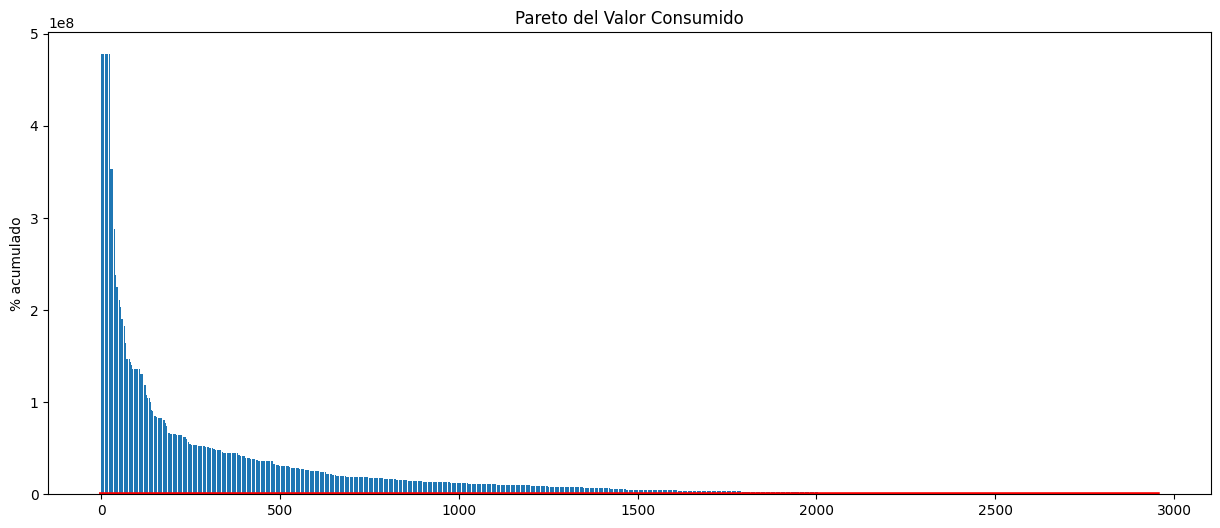

In [102]:
df_abc = df.sort_values("Valor Consumo", ascending=False)

plt.figure(figsize=(15,6))

plt.bar(
    range(len(df_abc)),
    df_abc["Valor Consumo"]
)

plt.plot(
    range(len(df_abc)),
    df_abc["Acumulado"]*100,
    color="red",
    linewidth=3
)

plt.ylabel("% acumulado")
plt.title("Pareto del Valor Consumido")
plt.show()

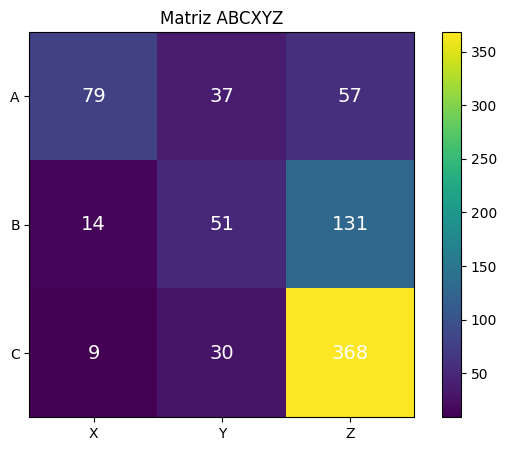

In [35]:
tabla=pd.crosstab(df["ABC"],df["XYZ"])

import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.imshow(tabla)

plt.xticks(range(3),tabla.columns)

plt.yticks(range(3),tabla.index)

for i in range(3):
    for j in range(3):
        plt.text(j,i,
                 tabla.iloc[i,j],
                 ha="center",
                 va="center",
                 color="white",
                 fontsize=14)

plt.title("Matriz ABCXYZ")
plt.colorbar()

plt.show()

> Interpretación para Supply Chain
> 
> Categoría	Interpretación	Política recomendada
> 
> AX	Alto valor y demanda estable	Máxima disponibilidad, pronósticos precisos, reposición frecuente.
> 
> AY	Alto valor con variabilidad media	Monitoreo continuo y revisión periódica de inventarios.
> 
> AZ	Alto valor y demanda errática	Compra bajo pedido, inventario de seguridad cuidadosamente calculado.
> 
> BX	Valor medio y demanda estable	Reposición estándar y control periódico.
> 
> BY	Valor medio y demanda variable	Revisiones más frecuentes y ajuste de parámetros.
> 
> BZ	Valor medio y demanda errática	Mantener inventario mínimo.
> 
> CX	Bajo valor y demanda estable	Pedidos grandes y poco frecuentes para reducir costos administrativos.
> 
> CY	Bajo valor con variabilidad media	Reposición según consumo histórico.
> 
> CZ	Bajo valor y demanda errática	Evaluar descontinuación o compra únicamente bajo pedido.


In [98]:
tabla = pd.crosstab(df["ABC"], df["XYZ"])

In [99]:
tabla_pct = tabla / tabla.values.sum() * 100

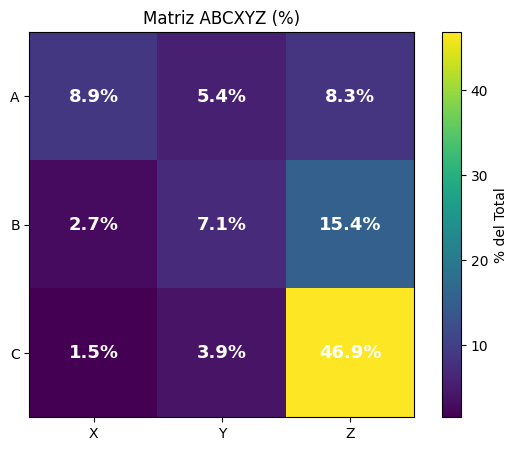

In [100]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.imshow(tabla_pct, cmap="viridis")

plt.xticks(range(len(tabla_pct.columns)), tabla_pct.columns)
plt.yticks(range(len(tabla_pct.index)), tabla_pct.index)

for i in range(tabla_pct.shape[0]):
    for j in range(tabla_pct.shape[1]):
        plt.text(
            j,
            i,
            f"{tabla_pct.iloc[i,j]:.1f}%",
            ha="center",
            va="center",
            color="white",
            fontsize=13,
            fontweight="bold"
        )

plt.colorbar(label="% del Total")
plt.title("Matriz ABCXYZ (%)")

plt.show()

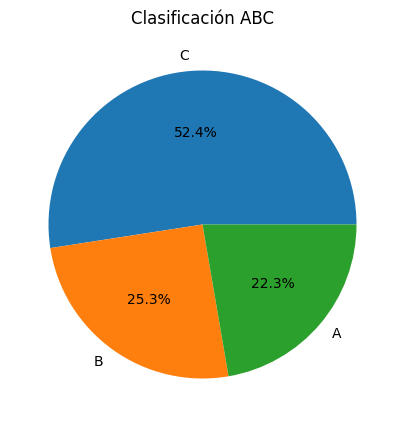

In [36]:
abc=df["ABC"].value_counts()

plt.figure(figsize=(6,5))
plt.pie(
    abc,
    labels=abc.index,
    autopct="%1.1f%%"
)

plt.title("Clasificación ABC")
plt.show()

In [37]:
familia=(

df.groupby("Familia")["Valor Consumo"]

.sum()

.sort_values(ascending=False)

.head(10)

)

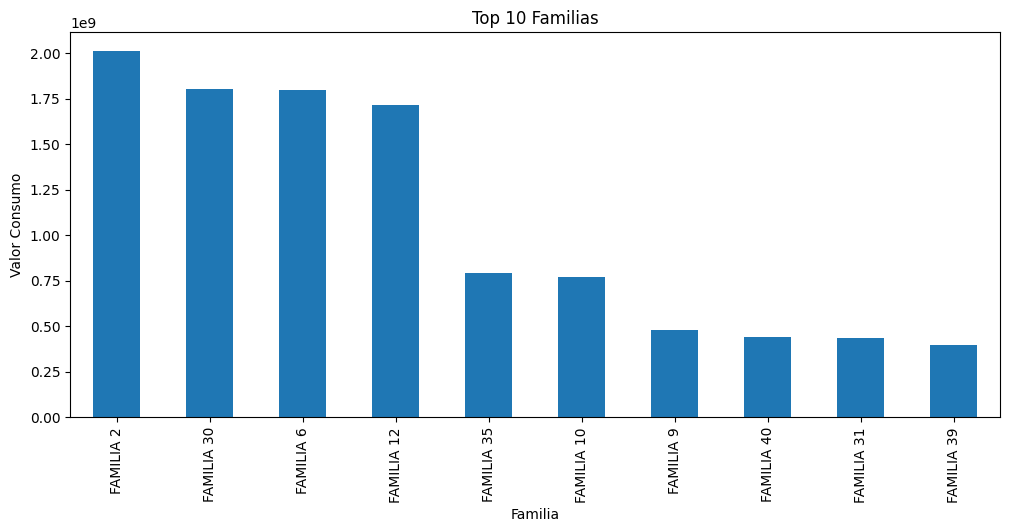

In [38]:
familia.plot(
kind="bar",
figsize=(12,5)
)

plt.ylabel("Valor Consumo")
plt.title("Top 10 Familias")
plt.show()

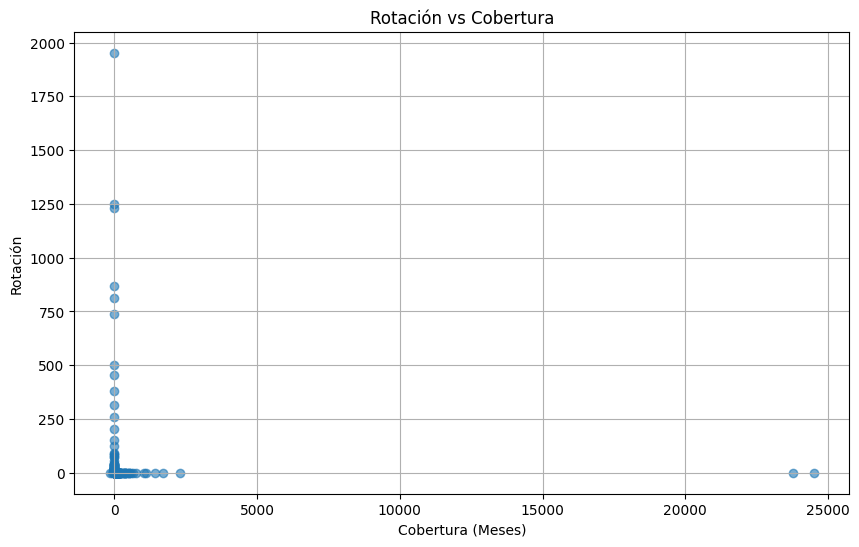

In [39]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["Cobertura Meses"],
    df["Rotacion"],
    alpha=0.6
)

plt.xlabel("Cobertura (Meses)")
plt.ylabel("Rotación")

plt.title("Rotación vs Cobertura")
plt.grid()

plt.show()

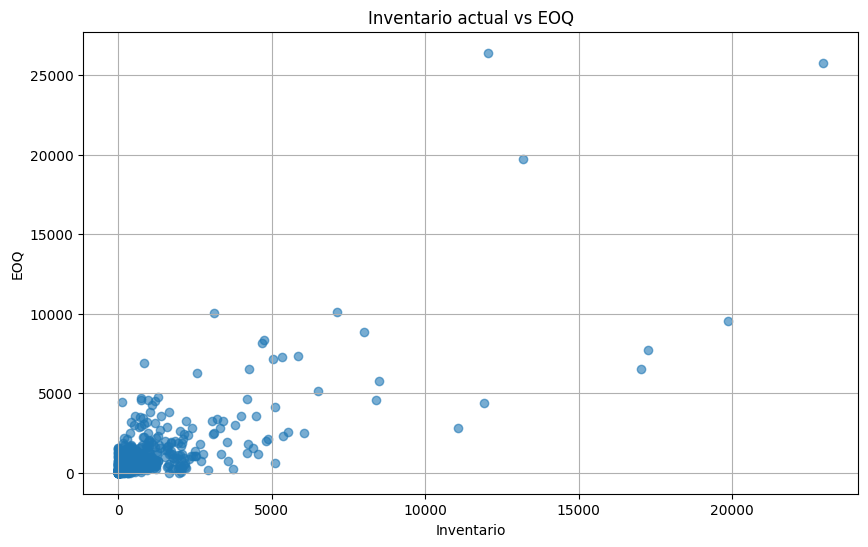

In [40]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["Inventario"],
    df["EOQ"],
    alpha=0.6
)

plt.xlabel("Inventario")

plt.ylabel("EOQ")

plt.title("Inventario actual vs EOQ")

plt.grid()

plt.show()

In [41]:
top=df.nlargest(20,"Punto Reorden")

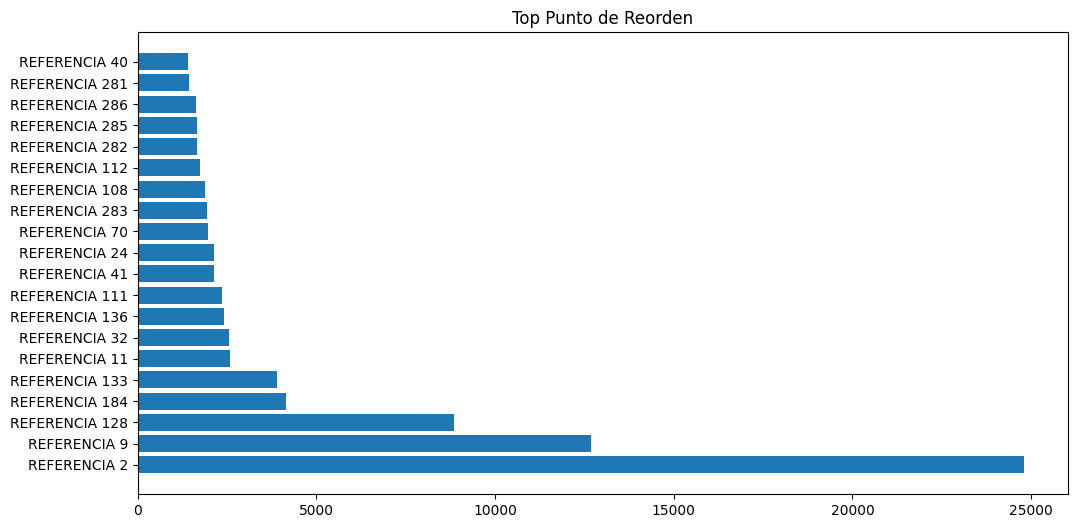

In [42]:
plt.figure(figsize=(12,6))

plt.barh(
top["Descripción"],
top["Punto Reorden"]
)

plt.title("Top Punto de Reorden")

plt.show()

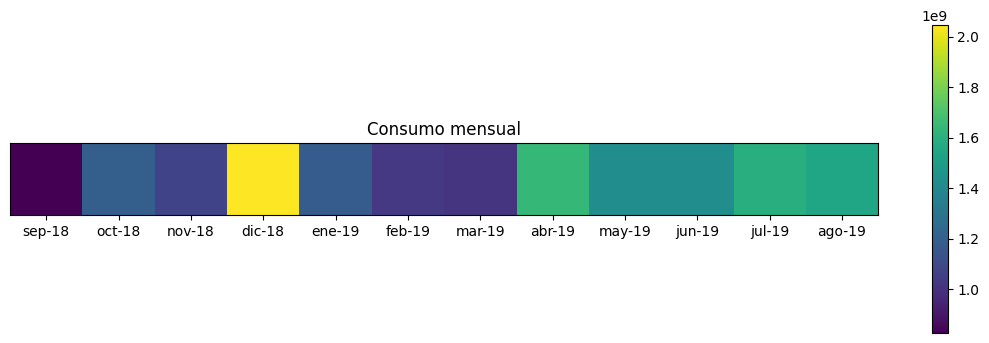

In [43]:
meses=[
'sep-18','oct-18','nov-18','dic-18',
'ene-19','feb-19','mar-19','abr-19',
'may-19','jun-19','jul-19','ago-19'
]

consumo=df[meses].sum()

plt.figure(figsize=(14,4))

plt.imshow([consumo])

plt.xticks(range(12),meses)

plt.yticks([])

plt.colorbar()

plt.title("Consumo mensual")

plt.show()

In [70]:
ubicacion = pd.read_csv(
    "ubicaciones.csv",
    sep=";",
    encoding="utf-8-sig"   # elimina el BOM (\ufeff) del inicio
)

ubicacion.info()
ubicacion.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1152 entries, 0 to 1151
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   X       1152 non-null   int64 
 1   Y       1152 non-null   object
 2   Z       1152 non-null   object
 3   SKU     1152 non-null   object
dtypes: int64(1), object(3)
memory usage: 36.1+ KB


,X,Y,Z,SKU
0,0,0,0,449081
1,0,"1,22",0,520308
2,0,"2,44",0,489773
3,0,"3,66",0,450216
4,0,"4,88",0,460000


In [71]:
#convertir la columna x y z en float
ubicacion["X"] = (
    ubicacion["X"]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .astype(float)
)
ubicacion["Y"] = (
    ubicacion["Y"]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .astype(float)
)
ubicacion["Z"] = (
    ubicacion["Z"]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .astype(float)
)

ubicacion.info()
ubicacion.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1152 entries, 0 to 1151
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       1152 non-null   float64
 1   Y       1152 non-null   float64
 2   Z       1152 non-null   float64
 3   SKU     1152 non-null   object 
dtypes: float64(3), object(1)
memory usage: 36.1+ KB


,X,Y,Z,SKU
0,0.0,0.00,0.0,449081
1,0.0,1.22,0.0,520308
2,0.0,2.44,0.0,489773
3,0.0,3.66,0.0,450216
4,0.0,4.88,0.0,460000


In [75]:
#traer de df la columna ABCXYZ y unirlo con el dataframe ubicacion
ubicacion = ubicacion.merge(
    df[["Código", "ABCXYZ"]],
    left_on="SKU",
    right_on="Código",
    how="left"
)

ubicacion.info()
ubicacion.head()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1999995 entries, 0 to 1999994
Data columns (total 10 columns):
 #   Column    Dtype  
---  ------    -----  
 0   X         float64
 1   Y         float64
 2   Z         float64
 3   SKU       object 
 4   Código_x  object 
 5   ABCXYZ_x  object 
 6   Código_y  object 
 7   ABCXYZ_y  object 
 8   Código    object 
 9   ABCXYZ    object 
dtypes: float64(3), object(7)
memory usage: 152.6+ MB


,X,Y,Z,SKU,Código_x,ABCXYZ_x,Código_y,ABCXYZ_y,Código,ABCXYZ
0,0.0,0.0,0.0,449081,449081,BY,449081,BY,449081,BY
1,0.0,0.0,0.0,449081,449081,BY,449081,BY,449081,BY
2,0.0,0.0,0.0,449081,449081,BY,449081,BY,449081,BY
3,0.0,0.0,0.0,449081,449081,BY,449081,BY,449081,BY
4,0.0,0.0,0.0,449081,449081,BY,449081,BY,449081,BY


In [82]:
ubicacion = ubicacion.drop_duplicates(subset="SKU", keep="first").reset_index(drop=True)

In [84]:
ubicacion.info()
ubicacion.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 606 entries, 0 to 605
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       606 non-null    float64
 1   Y       606 non-null    float64
 2   Z       606 non-null    float64
 3   SKU     606 non-null    object 
 4   ABCXYZ  606 non-null    object 
dtypes: float64(3), object(2)
memory usage: 23.8+ KB


,X,Y,Z,SKU,ABCXYZ
0,0.0,0.00,0.0,449081,BY
1,0.0,1.22,0.0,520308,CZ
2,0.0,2.44,0.0,489773,CY
3,0.0,3.66,0.0,450216,BZ
4,0.0,4.88,0.0,460000,BY


In [85]:
prioridad = {
    "AX":9,
    "AY":8,
    "AZ":7,
    "BX":6,
    "BY":5,
    "BZ":4,
    "CX":3,
    "CY":2,
    "CZ":1
}

ubicacion["Prioridad"] = ubicacion["ABCXYZ"].map(prioridad)

In [86]:
colores = {

    "AX":"red",
    "AY":"orangered",
    "AZ":"orange",

    "BX":"gold",
    "BY":"yellow",
    "BZ":"khaki",

    "CX":"lime",
    "CY":"green",
    "CZ":"darkgreen"

}

ubicacion["Color"] = ubicacion["ABCXYZ"].map(colores)

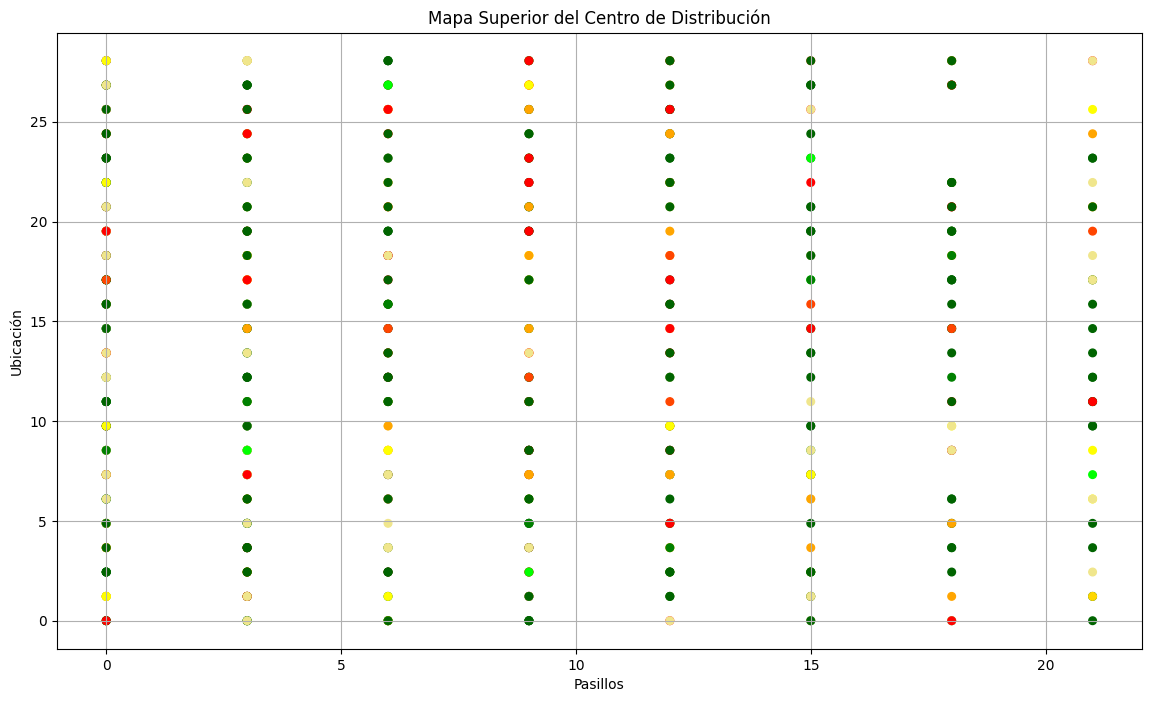

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,8))

plt.scatter(
    ubicacion["X"],
    ubicacion["Y"],
    c=ubicacion["Color"],
    s=30
)

plt.xlabel("Pasillos")

plt.ylabel("Ubicación")

plt.title("Mapa Superior del Centro de Distribución")

plt.grid()

plt.show()

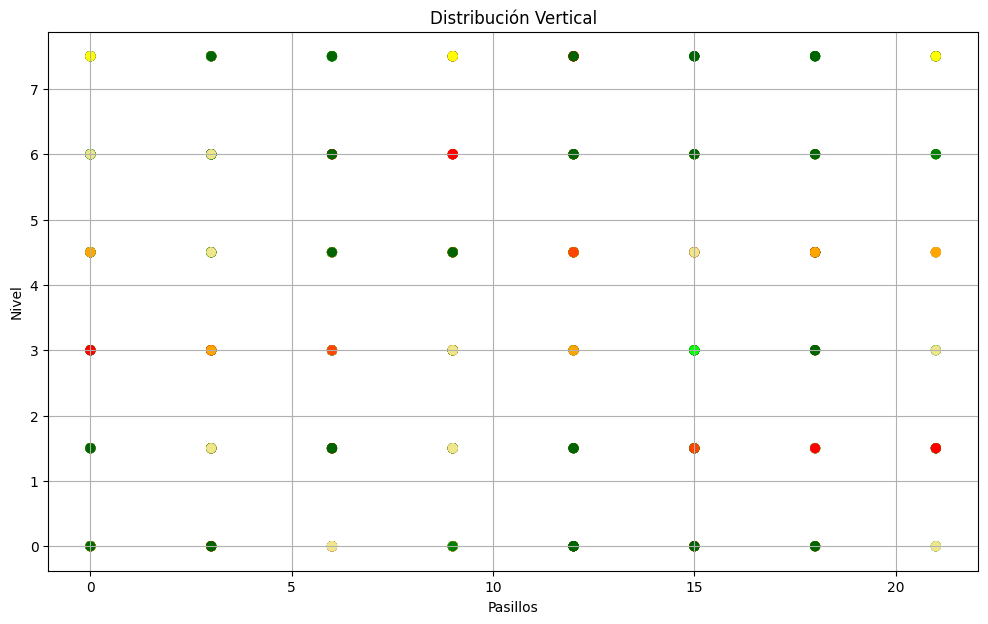

In [88]:
plt.figure(figsize=(12,7))

plt.scatter(
    ubicacion["X"],
    ubicacion["Z"],
    c=ubicacion["Color"],
    s=40
)

plt.xlabel("Pasillos")

plt.ylabel("Nivel")

plt.title("Distribución Vertical")

plt.grid()

plt.show()

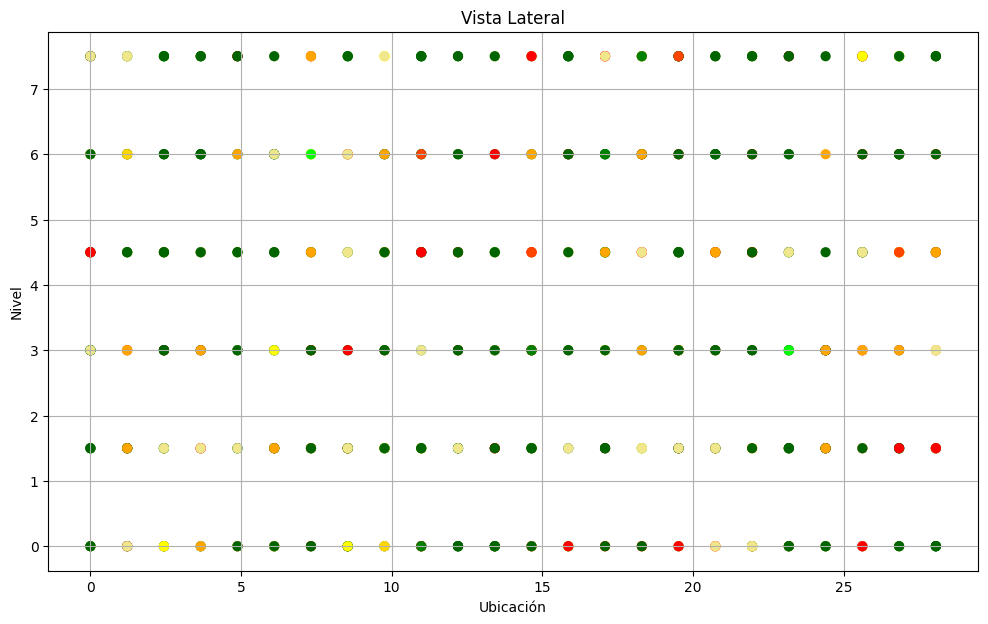

In [89]:
plt.figure(figsize=(12,7))

plt.scatter(
    ubicacion["Y"],
    ubicacion["Z"],
    c=ubicacion["Color"],
    s=40
)

plt.xlabel("Ubicación")

plt.ylabel("Nivel")

plt.title("Vista Lateral")

plt.grid()

plt.show()

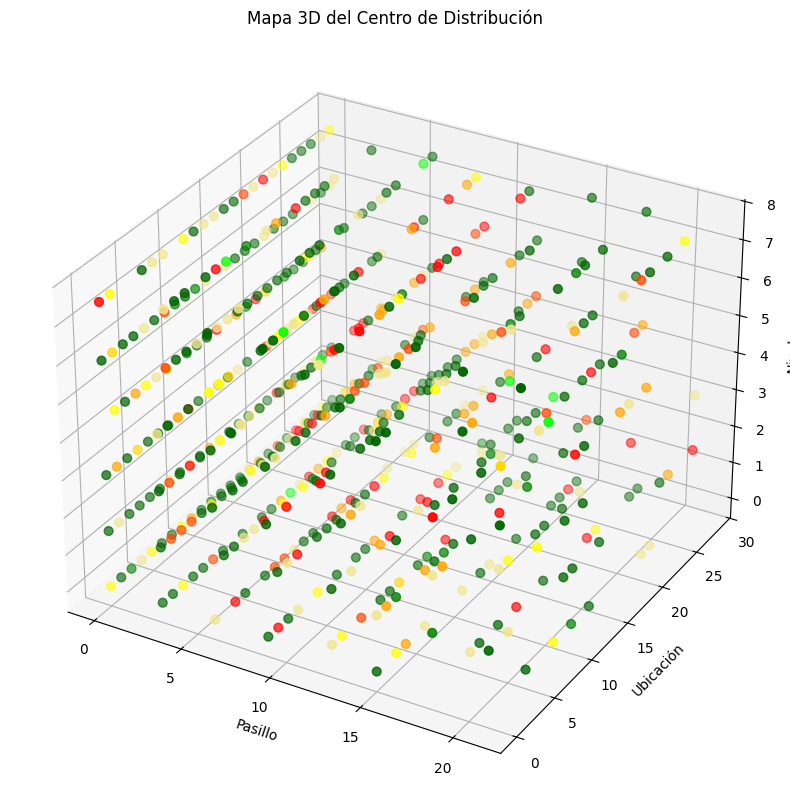

In [90]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(14,10))

ax = fig.add_subplot(
    111,
    projection="3d"
)

ax.scatter(

    ubicacion["X"],

    ubicacion["Y"],

    ubicacion["Z"],

    c=ubicacion["Color"],

    s=40

)

ax.set_xlabel("Pasillo")

ax.set_ylabel("Ubicación")

ax.set_zlabel("Nivel")

plt.title("Mapa 3D del Centro de Distribución")

plt.show()

In [92]:
heat = ubicacion.pivot_table(

    index="Y",

    columns="X",

    values="Prioridad",

    aggfunc="mean"

)

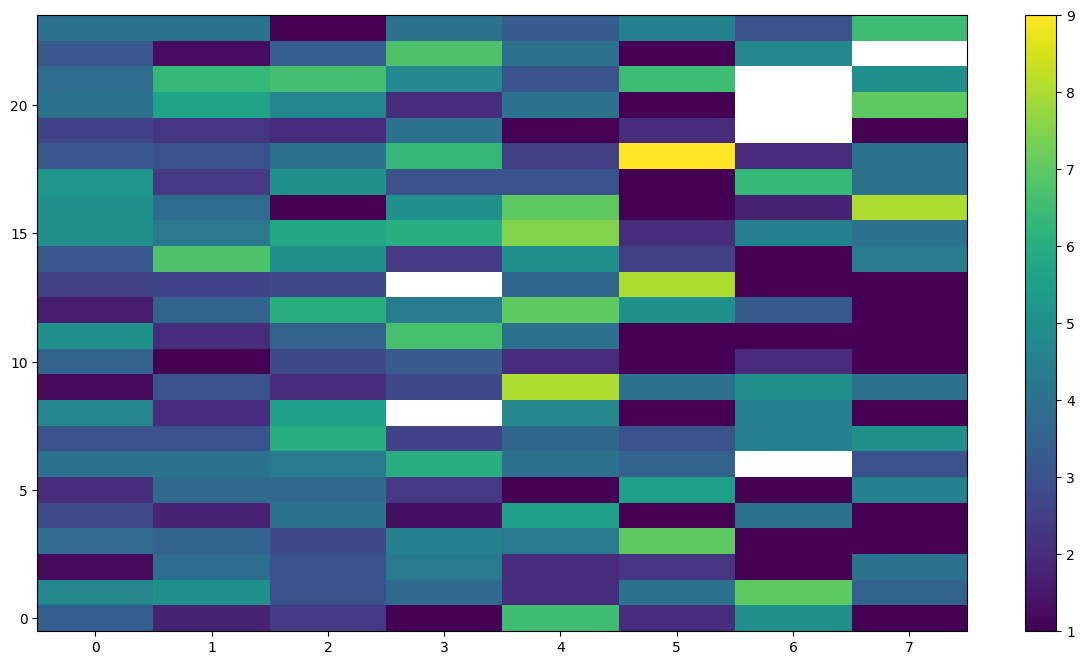

In [93]:
plt.figure(figsize=(15,8))

plt.imshow(

    heat,

    origin="lower",

    aspect="auto"

)

plt.colorbar()

plt.show()

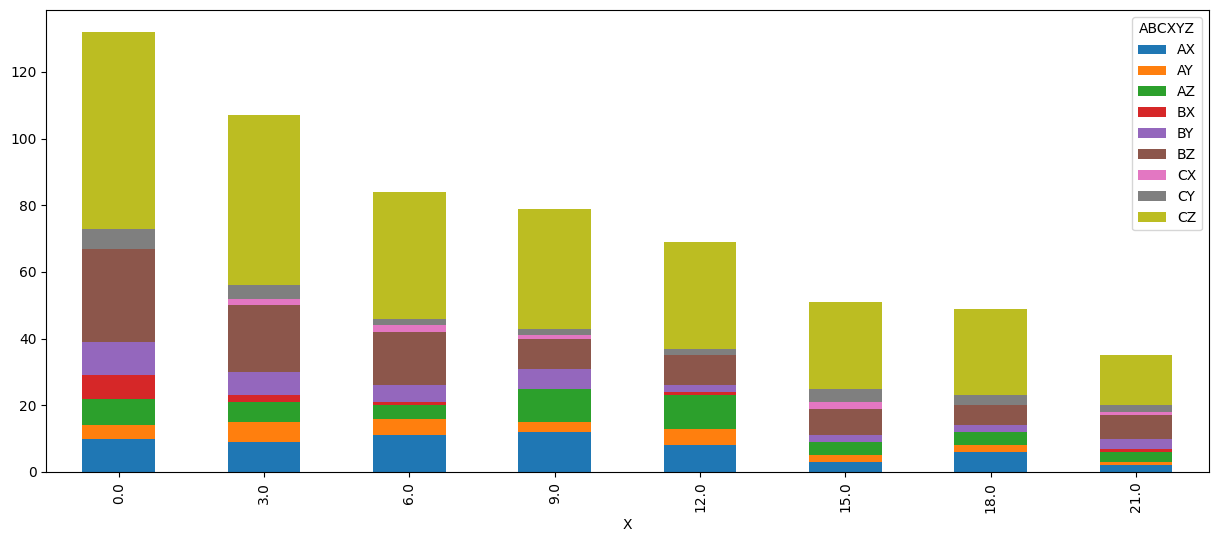

In [94]:
pasillo = (
    ubicacion
    .groupby(["X","ABCXYZ"])
    .size()
    .unstack(fill_value=0)
)

pasillo.plot(
    kind="bar",
    stacked=True,
    figsize=(15,6)
)

plt.show()

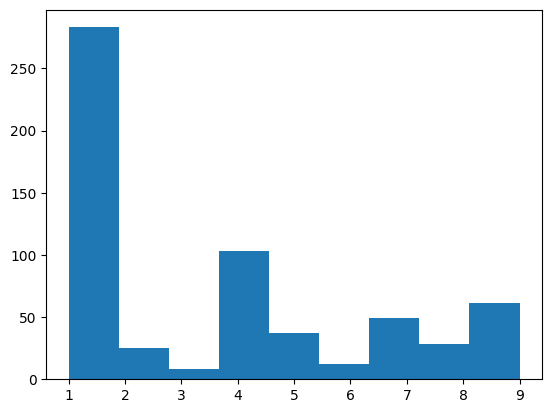

In [95]:
plt.hist(

    ubicacion["Prioridad"],

    bins=9

)

plt.show()

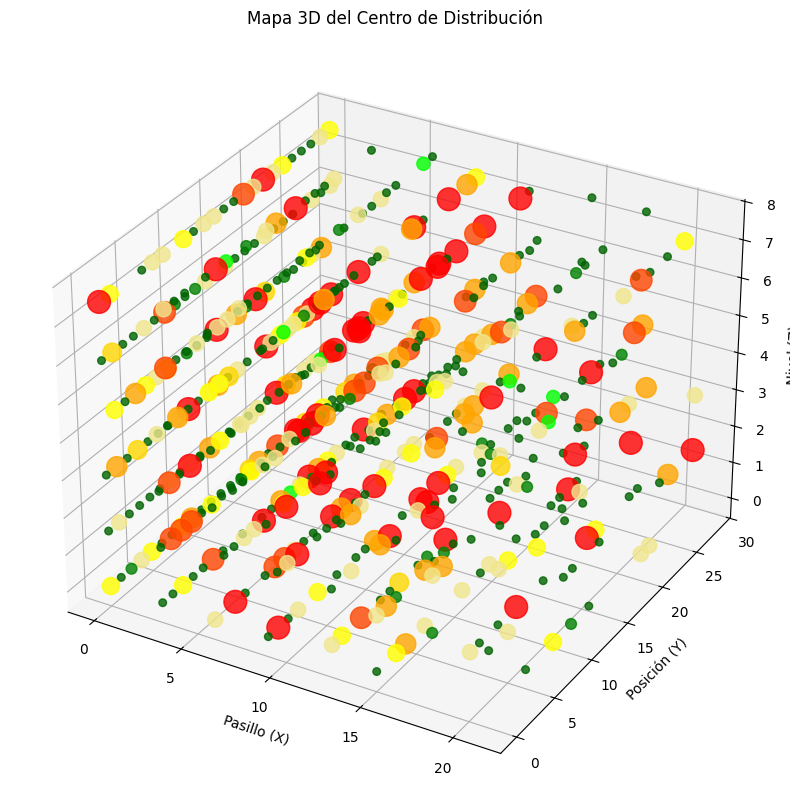

In [97]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12,10))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    ubicacion["X"],
    ubicacion["Y"],
    ubicacion["Z"],
    c=ubicacion["Color"],
    s=ubicacion["Prioridad"] * 30,
    alpha=0.8
)

ax.set_xlabel("Pasillo (X)")
ax.set_ylabel("Posición (Y)")
ax.set_zlabel("Nivel (Z)")

plt.title("Mapa 3D del Centro de Distribución")

plt.show()